In [1]:

from pathlib import Path
import json
import pandas as pd
import pyarrow.parquet as pq

# Find the repository root
root = Path.cwd()
if not (root / "data/processed").exists():
    root = root.parent

data_path = root / "data/processed/patch_model_eligible_terrain_v2.parquet"
roles_path = root / "data/processed/patch_model_eligible_terrain_v2.roles.json"

assert data_path.exists(), "Dataset not found"
assert roles_path.exists(), "Feature roles not found"

# Load column-role definitions
with open(roles_path, "r") as f:
    roles = json.load(f)

# Inspect the dataset without reading any target values
parquet = pq.ParquetFile(data_path)

print("Dataset rows:", parquet.metadata.num_rows)
print("Dataset columns:", len(parquet.schema_arrow.names))
print("\nRoles JSON structure:")
print(json.dumps(roles, indent=2)[:3000])


Dataset rows: 111257
Dataset columns: 129

Roles JSON structure:
{
  "target": "nbr_5_mean",
  "predictors": [
    "nbr_pre_mean",
    "dominant_evt",
    "dominant_evt_fraction",
    "tree_cover_mean",
    "tree_height_mean",
    "elevation_mean",
    "slope_mean",
    "northness_mean",
    "eastness_mean",
    "fire_size_acres",
    "ignition_month",
    "mtbs_unburned_low_fraction",
    "mtbs_low_fraction",
    "mtbs_moderate_fraction",
    "mtbs_high_fraction",
    "mtbs_increased_greenness_fraction",
    "hist_prcp_mm",
    "hist_tmax_c",
    "hist_tmin_c",
    "hist_s1_vpd_kpa",
    "nbr_1_mean",
    "pre_s1_prcp_mm",
    "pre_s1_tmax_c",
    "pre_s1_tmin_c",
    "pre_s1_vpd_kpa",
    "pre_s1_prcp_anom_mm",
    "pre_s1_tmax_anom_c",
    "pre_s1_tmin_anom_c",
    "pre_s1_vpd_anom_kpa",
    "s1_prcp_anom_mm",
    "s1_tmax_anom_c",
    "s1_tmin_anom_c",
    "s1_vpd_anom_kpa",
    "nbr_drop_patch"
  ],
  "early_predictors": [
    "nbr_pre_mean",
    "dominant_evt",
    "dominant_evt_

In [2]:

# Approved inputs and target
features = roles["predictors"]
target = roles["target"]

assert len(features) == 34
assert target not in features

keys = ["fire_id", "patch_id", "split"]

# Load approved inputs for all splits
inputs = pd.read_parquet(
    data_path,
    columns=keys + features
)

# Load targets ONLY for training and validation
dev_targets = pd.read_parquet(
    data_path,
    columns=keys + [target],
    filters=[("split", "in", ["train", "validation"])]
)

# Combine inputs and labels for development data
dev = inputs.loc[
    inputs["split"].isin(["train", "validation"])
].merge(
    dev_targets,
    on=keys,
    validate="one_to_one"
)

train = dev.loc[dev["split"] == "train"].copy()
val = dev.loc[dev["split"] == "validation"].copy()

# Separate predictors (X) and target (y)
X_train, y_train = train[features], train[target]
X_val, y_val = val[features], val[target]

# Safety checks
assert len(train) == 61090
assert len(val) == 19561
assert inputs["split"].eq("test").sum() == 30606
assert train["fire_id"].nunique() == 78
assert val["fire_id"].nunique() == 36
assert set(train["fire_id"]).isdisjoint(val["fire_id"])
assert y_train.notna().all() and y_val.notna().all()

print("Training:", X_train.shape, "| Fires:", train["fire_id"].nunique())
print("Validation:", X_val.shape, "| Fires:", val["fire_id"].nunique())
print("Test inputs:", inputs["split"].eq("test").sum())
print("Target:", target)
print("Approved features:", len(features))


Training: (61090, 34) | Fires: 78
Validation: (19561, 34) | Fires: 36
Test inputs: 30606
Target: nbr_5_mean
Approved features: 34


In [3]:

import numpy as np
import sklearn
print(sklearn.__version__)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Learn the average NBR5 from TRAINING data only
train_mean = y_train.mean()

# 2. Predict that same value for every validation patch
mean_predictions = np.full(len(y_val), train_mean)

# 3. Calculate prediction errors
mae = mean_absolute_error(y_val, mean_predictions)
rmse = np.sqrt(mean_squared_error(y_val, mean_predictions))
r2 = r2_score(y_val, mean_predictions)

# 4. Give each validation wildfire equal importance
errors = pd.DataFrame({
    "fire_id": val["fire_id"].to_numpy(),
    "absolute_error": np.abs(y_val.to_numpy() - mean_predictions)
})

equal_fire_mae = (
    errors.groupby("fire_id")["absolute_error"]
    .mean()
    .mean()
)

print("MEAN BASELINE — VALIDATION RESULTS")
print(f"Training mean NBR5: {train_mean:.4f}")
print(f"Validation MAE:      {mae:.4f}")
print(f"Validation RMSE:     {rmse:.4f}")
print(f"Validation R²:       {r2:.4f}")
print(f"Equal-fire MAE:      {equal_fire_mae:.4f}")


1.9.1
MEAN BASELINE — VALIDATION RESULTS
Training mean NBR5: 0.3122
Validation MAE:      0.1624
Validation RMSE:     0.1932
Validation R²:       -0.0255
Equal-fire MAE:      0.1421


In [4]:

# Predict NBR5 using each patch's observed NBR1
persistence_predictions = X_val["nbr_1_mean"].to_numpy()

# Calculate validation prediction errors
persistence_mae = mean_absolute_error(
    y_val, persistence_predictions
)
persistence_rmse = np.sqrt(
    mean_squared_error(y_val, persistence_predictions)
)
persistence_r2 = r2_score(
    y_val, persistence_predictions
)

# Give each wildfire equal weight
persistence_errors = pd.DataFrame({
    "fire_id": val["fire_id"].to_numpy(),
    "absolute_error": np.abs(
        y_val.to_numpy() - persistence_predictions
    )
})

persistence_equal_fire_mae = (
    persistence_errors.groupby("fire_id")["absolute_error"]
    .mean()
    .mean()
)

print("PERSISTENCE BASELINE — VALIDATION RESULTS")
print(f"Validation MAE:     {persistence_mae:.4f}")
print(f"Validation RMSE:    {persistence_rmse:.4f}")
print(f"Validation R²:      {persistence_r2:.4f}")
print(f"Equal-fire MAE:     {persistence_equal_fire_mae:.4f}")

# Compare both baselines
comparison = pd.DataFrame({
    "Model": ["Training mean", "NBR1 persistence"],
    "MAE": [mae, persistence_mae],
    "RMSE": [rmse, persistence_rmse],
    "R²": [r2, persistence_r2],
    "Equal-fire MAE": [equal_fire_mae, persistence_equal_fire_mae]
})

print("\nBASELINE COMPARISON")
display(comparison.round(4))


PERSISTENCE BASELINE — VALIDATION RESULTS
Validation MAE:     0.1839
Validation RMSE:    0.2423
Validation R²:      -0.6139
Equal-fire MAE:     0.1585

BASELINE COMPARISON


,Model,MAE,RMSE,R²,Equal-fire MAE
0,Training mean,0.1624,0.1932,-0.0255,0.1421
1,NBR1 persistence,0.1839,0.2423,-0.6139,0.1585


In [5]:

import mlflow

# Store experiment records in a local SQLite database
db_path = root / "mlflow.db"

mlflow.set_tracking_uri(
    f"sqlite:///{db_path.as_posix()}"
)

mlflow.set_experiment("P1 - Wildfire Recovery - Phase 5")

print("MLflow version:", mlflow.__version__)
print("Tracking location:", mlflow.get_tracking_uri())
print("Experiment ready!")


MLflow version: 3.17.2
Tracking location: sqlitmlflow.db
Experiment ready!


In [6]:

# Shared information about our experiments
experiment_info = {
    "dataset": "patch_model_eligible_terrain_v2",
    "train_years": "2015-2017",
    "validation_years": "2018-2019",
    "train_fires": 78,
    "validation_fires": 36,
}

# Experiment 1: Training-mean baseline
with mlflow.start_run(run_name="baseline_training_mean"):
    mlflow.log_params({
        **experiment_info,
        "strategy": "predict_training_mean",
        "constant_prediction": float(train_mean),
    })

    mlflow.log_metrics({
        "val_mae": float(mae),
        "val_rmse": float(rmse),
        "val_r2": float(r2),
        "val_equal_fire_mae": float(equal_fire_mae),
    })

print("Logged training-mean baseline!")

# Experiment 2: NBR1 persistence baseline
with mlflow.start_run(run_name="baseline_nbr1_persistence"):
    mlflow.log_params({
        **experiment_info,
        "strategy": "predict_nbr1",
        "predictor": "nbr_1_mean",
    })

    mlflow.log_metrics({
        "val_mae": float(persistence_mae),
        "val_rmse": float(persistence_rmse),
        "val_r2": float(persistence_r2),
        "val_equal_fire_mae": float(persistence_equal_fire_mae),
    })

print("Logged NBR1 persistence baseline!")

# Retrieve both experiments from MLflow
runs = mlflow.search_runs(
    experiment_names=["P1 - Wildfire Recovery - Phase 5"]
)

display(
    runs[
        [
            "tags.mlflow.runName",
            "metrics.val_mae",
            "metrics.val_rmse",
            "metrics.val_r2",
            "metrics.val_equal_fire_mae",
        ]
    ].round(4)
)


Logged training-mean baseline!
Logged NBR1 persistence baseline!


,tags.mlflow.runName,metrics.val_mae,metrics.val_rmse,metrics.val_r2,metrics.val_equal_fire_mae
0,baseline_nbr1_persistence,0.1839,0.2423,-0.6139,0.1585
1,baseline_training_mean,0.1624,0.1932,-0.0255,0.1421
2,baseline_nbr1_persistence,0.1839,0.2423,-0.6139,0.1585
3,baseline_training_mean,0.1624,0.1932,-0.0255,0.1421
4,ridge2_severity_interaction,0.1131,0.1404,0.4580,0.1132
5,ridge_alpha_3000,0.1131,0.1403,0.4588,0.1128
6,baseline_nbr1_persistence,0.1839,0.2423,-0.6139,0.1585
7,baseline_training_mean,0.1624,0.1932,-0.0255,0.1421
8,baseline_nbr1_persistence,0.1839,0.2423,-0.6139,0.1585
9,baseline_training_mean,0.1624,0.1932,-0.0255,0.1421


In [7]:
from wildfire_recovery_forecasting.evaluation import evaluate_model

# Check that the function reproduces our original results
mean_scores = evaluate_model(
    y_val, mean_predictions, val["fire_id"]
)

persistence_scores = evaluate_model(
    y_val, persistence_predictions, val["fire_id"]
)

assert np.isclose(mean_scores["mae"], mae)
assert np.isclose(mean_scores["equal_fire_mae"], equal_fire_mae)
assert np.isclose(persistence_scores["mae"], persistence_mae)
assert np.isclose(
    persistence_scores["equal_fire_mae"],
    persistence_equal_fire_mae
)

display(pd.DataFrame({
    "Training mean": mean_scores,
    "NBR1 persistence": persistence_scores
}).T.round(4))

print("Reusable evaluation function verified!")


,mae,rmse,r2,equal_fire_mae
Training mean,0.1624,0.1932,-0.0255,0.1421
NBR1 persistence,0.1839,0.2423,-0.6139,0.1585


Reusable evaluation function verified!


# RIDGE REGRESSION

In [8]:

# Phase 5 Day 2 — Confirm Ridge modeling inputs

categorical_features = [
    "dominant_evt",
    "ignition_month",
]

# Drop only the exactly redundant NBR difference for Ridge
ridge_features = [
    f for f in features
    if f != "nbr_drop_patch"
]

numeric_features = [
    f for f in ridge_features
    if f not in categorical_features
]

assert len(features) == 34
assert len(ridge_features) == 33
assert len(numeric_features) == 31

assert len(X_train) == 61090
assert len(X_val) == 19561

print("Training patches:", len(X_train))
print("Validation patches:", len(X_val))
print("Ridge input features:", len(ridge_features))
print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

print("\nMissing training feature values:")
print(X_train[ridge_features].isna().sum().sum())

print("\nCategorical feature types:")
print(X_train[categorical_features].dtypes)


Training patches: 61090
Validation patches: 19561
Ridge input features: 33
Numerical features: 31
Categorical features: ['dominant_evt', 'ignition_month']

Missing training feature values:
0

Categorical feature types:
dominant_evt      int64
ignition_month    int64
dtype: object


In [9]:
from wildfire_recovery_forecasting.modeling import build_ridge_pipeline

ridge_pipeline = build_ridge_pipeline(features, alpha=1.0)
preprocessor = ridge_pipeline.named_steps["preprocess"]

# 3. Check that validation inputs are also complete
assert X_val[ridge_features].notna().all().all()

print("Ridge pipeline created!")
print("\nPipeline steps:")
for name, component in ridge_pipeline.steps:
    print(f"  {name}: {component.__class__.__name__}")

print("\nNumerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Ready for training and cross-validation.")


Ridge pipeline created!

Pipeline steps:
  preprocess: ColumnTransformer
  model: Ridge

Numerical features: 31
Categorical features: 2
Ready for training and cross-validation.


In [10]:

from sklearn.model_selection import GroupKFold

# Each patch belongs to a wildfire
groups = train["fire_id"]

# Create three folds, keeping each fire together
cv = GroupKFold(n_splits=3)

cv_splits = list(
    cv.split(
        X_train[ridge_features],
        y_train,
        groups=groups
    )
)

summary = []

for fold, (train_idx, holdout_idx) in enumerate(cv_splits, 1):

    training_fires = set(groups.iloc[train_idx])
    holdout_fires = set(groups.iloc[holdout_idx])

    # A fire must never appear in both groups
    assert training_fires.isdisjoint(holdout_fires)

    summary.append({
        "Fold": fold,
        "Training patches": len(train_idx),
        "Held-out patches": len(holdout_idx),
        "Training fires": len(training_fires),
        "Held-out fires": len(holdout_fires),
        "Fire overlap": len(training_fires & holdout_fires)
    })

assert sum(len(v) for _, v in cv_splits) == len(train)

display(pd.DataFrame(summary))

print("3-fold fire-grouped CV ready!")


,Fold,Training patches,Held-out patches,Training fires,Held-out fires,Fire overlap
0,1,40727,20363,51,27,0
1,2,40726,20364,53,25,0
2,3,40727,20363,52,26,0


3-fold fire-grouped CV ready!


In [11]:

from sklearn.base import clone

# Four regularization strengths to compare
alphas = [0.1, 1.0, 10.0, 100.0]

cv_results = []

for alpha in alphas:
    fold_maes = []

    for train_idx, holdout_idx in cv_splits:

        # Create a fresh preprocessing + Ridge pipeline
        model = clone(ridge_pipeline)
        model.set_params(model__alpha=alpha)

        # Train on this fold's training fires only
        model.fit(
            X_train.iloc[train_idx][ridge_features],
            y_train.iloc[train_idx]
        )

        # Predict NBR5 for held-out training fires
        predictions = model.predict(
            X_train.iloc[holdout_idx][ridge_features]
        )

        fold_maes.append(
            mean_absolute_error(
                y_train.iloc[holdout_idx],
                predictions
            )
        )

    cv_results.append({
        "alpha": alpha,
        "fold_1_mae": fold_maes[0],
        "fold_2_mae": fold_maes[1],
        "fold_3_mae": fold_maes[2],
        "mean_cv_mae": np.mean(fold_maes),
        "std_cv_mae": np.std(fold_maes)
    })

cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values("mean_cv_mae")
)

display(cv_results_df.round(5))

best_alpha = float(cv_results_df.iloc[0]["alpha"])

print(f"Best alpha from grouped CV: {best_alpha}")


,alpha,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,std_cv_mae
3,100.0,0.07552,0.07420,0.08281,0.07751,0.00378
2,10.0,0.07727,0.07601,0.09038,0.08122,0.00650
1,1.0,0.07810,0.07782,0.09241,0.08278,0.00681
0,0.1,0.07824,0.07813,0.09269,0.08302,0.00684


Best alpha from grouped CV: 100.0


In [12]:

more_alphas = [300.0, 1000.0, 3000.0]
additional_results = []

for alpha in more_alphas:
    fold_maes = []

    for train_idx, holdout_idx in cv_splits:
        model = clone(ridge_pipeline)
        model.set_params(model__alpha=alpha)

        model.fit(
            X_train.iloc[train_idx][ridge_features],
            y_train.iloc[train_idx]
        )

        predictions = model.predict(
            X_train.iloc[holdout_idx][ridge_features]
        )

        fold_maes.append(
            mean_absolute_error(
                y_train.iloc[holdout_idx],
                predictions
            )
        )

    additional_results.append({
        "alpha": alpha,
        "fold_1_mae": fold_maes[0],
        "fold_2_mae": fold_maes[1],
        "fold_3_mae": fold_maes[2],
        "mean_cv_mae": np.mean(fold_maes),
        "std_cv_mae": np.std(fold_maes)
    })

# Compare all seven alpha settings
cv_results_df = (
    pd.concat(
        [cv_results_df, pd.DataFrame(additional_results)],
        ignore_index=True
    )
    .drop_duplicates(subset="alpha", keep="last")
    .sort_values("mean_cv_mae")
    .reset_index(drop=True)
)

display(cv_results_df.round(5))

best_alpha = float(cv_results_df.iloc[0]["alpha"])
print(f"Current best alpha: {best_alpha}")


,alpha,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,std_cv_mae
0,3000.0,0.07256,0.07983,0.07038,0.07425,0.00404
1,1000.0,0.07352,0.07794,0.07261,0.07469,0.00233
2,300.0,0.07475,0.07571,0.07756,0.07600,0.00117
3,100.0,0.07552,0.07420,0.08281,0.07751,0.00378
4,10.0,0.07727,0.07601,0.09038,0.08122,0.00650
5,1.0,0.07810,0.07782,0.09241,0.08278,0.00681
6,0.1,0.07824,0.07813,0.09269,0.08302,0.00684


Current best alpha: 3000.0


In [13]:

final_alphas = [10000.0, 30000.0, 100000.0]
final_results = []

for alpha in final_alphas:
    fold_maes = []

    for train_idx, holdout_idx in cv_splits:
        model = clone(ridge_pipeline)
        model.set_params(model__alpha=alpha)

        model.fit(
            X_train.iloc[train_idx][ridge_features],
            y_train.iloc[train_idx]
        )

        predictions = model.predict(
            X_train.iloc[holdout_idx][ridge_features]
        )

        fold_maes.append(
            mean_absolute_error(
                y_train.iloc[holdout_idx],
                predictions
            )
        )

    final_results.append({
        "alpha": alpha,
        "fold_1_mae": fold_maes[0],
        "fold_2_mae": fold_maes[1],
        "fold_3_mae": fold_maes[2],
        "mean_cv_mae": np.mean(fold_maes),
        "std_cv_mae": np.std(fold_maes)
    })

cv_results_df = (
    pd.concat(
        [cv_results_df, pd.DataFrame(final_results)],
        ignore_index=True
    )
    .drop_duplicates(subset="alpha")
    .sort_values("mean_cv_mae")
    .reset_index(drop=True)
)

display(cv_results_df.round(5))

best_alpha = float(cv_results_df.iloc[0]["alpha"])
print("Selected alpha:", best_alpha)


,alpha,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,std_cv_mae
0,3000.0,0.07256,0.07983,0.07038,0.07425,0.00404
1,1000.0,0.07352,0.07794,0.07261,0.07469,0.00233
2,10000.0,0.07376,0.08355,0.07003,0.07578,0.00570
3,300.0,0.07475,0.07571,0.07756,0.07600,0.00117
4,100.0,0.07552,0.07420,0.08281,0.07751,0.00378
5,10.0,0.07727,0.07601,0.09038,0.08122,0.00650
6,30000.0,0.07923,0.09213,0.07464,0.08200,0.00741
7,1.0,0.07810,0.07782,0.09241,0.08278,0.00681
8,0.1,0.07824,0.07813,0.09269,0.08302,0.00684
9,100000.0,0.09307,0.11033,0.08728,0.09690,0.00979


Selected alpha: 3000.0


In [14]:

# Train Ridge on ALL training fires using selected alpha
final_ridge = clone(ridge_pipeline)
final_ridge.set_params(model__alpha=best_alpha)

final_ridge.fit(
    X_train[ridge_features],
    y_train
)

# Predict for 2018–2019 validation fires
ridge_predictions = final_ridge.predict(
    X_val[ridge_features]
)

# Evaluate using our reusable function
ridge_scores = evaluate_model(
    y_val,
    ridge_predictions,
    val["fire_id"]
)

print(f"RIDGE VALIDATION RESULTS — alpha={best_alpha:g}")
display(pd.Series(ridge_scores).round(5))

# Compare all three prediction approaches
comparison = pd.DataFrame({
    "Training mean": mean_scores,
    "NBR1 persistence": persistence_scores,
    "Ridge regression": ridge_scores,
}).T

print("\nVALIDATION MODEL COMPARISON")
display(comparison.round(5))


RIDGE VALIDATION RESULTS — alpha=3000


mae               0.11308
rmse              0.14032
r2                0.45881
equal_fire_mae    0.11276
dtype: float64


VALIDATION MODEL COMPARISON


,mae,rmse,r2,equal_fire_mae
Training mean,0.16244,0.19316,-0.02555,0.14215
NBR1 persistence,0.18389,0.24230,-0.61385,0.15851
Ridge regression,0.11308,0.14032,0.45881,0.11276


In [15]:

import mlflow

mlflow.set_experiment("P1 - Wildfire Recovery - Phase 5")

with mlflow.start_run(run_name="ridge_alpha_3000") as run:
    mlflow.log_params({
        "model": "Ridge",
        "alpha": best_alpha,
        "dataset": "patch_model_eligible_terrain_v2",
        "n_features": len(ridge_features),
        "excluded_feature": "nbr_drop_patch",
        "cv_method": "GroupKFold",
        "cv_folds": 3,
        "train_fires": 78,
        "validation_fires": 36,
    })

    mlflow.log_metrics({
        "cv_mae": float(cv_results_df.iloc[0]["mean_cv_mae"]),
        "cv_std_mae": float(cv_results_df.iloc[0]["std_cv_mae"]),
        **{
            f"val_{name}": float(value)
            for name, value in ridge_scores.items()
        },
    })

    # Save the fitted preprocessing + Ridge model
    mlflow.sklearn.log_model(
        sk_model=final_ridge,
        name="ridge_pipeline",
    )

print("Ridge experiment recorded!")
print("MLflow run ID:", run.info.run_id)


2026/10/31 14:34:20 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Ridge experiment recorded!
MLflow run ID: 88c26409c33d4640abbb6e6ddff1e0ed


In [16]:

# RIDGE2 — EDA-inspired NBRpre × burn severity interaction

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge

interaction_name = "nbrpre_x_highseverity"

# Add the interaction to training and validation inputs
X_train_ridge2 = X_train[ridge_features].copy()
X_val_ridge2 = X_val[ridge_features].copy()

for X in [X_train_ridge2, X_val_ridge2]:
    X[interaction_name] = (
        X["nbr_pre_mean"] * X["mtbs_high_fraction"]
    )

# Ridge2 now has 32 numerical + 2 categorical inputs
ridge2_numeric = numeric_features + [interaction_name]

ridge2_pipeline = Pipeline([
    ("preprocess", ColumnTransformer([
        ("numeric", StandardScaler(), ridge2_numeric),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
    ])),
    ("model", Ridge(alpha=best_alpha))
])

# 1. Evaluate Ridge2 on our SAME 3 grouped CV folds
ridge2_fold_maes = []

for train_idx, holdout_idx in cv_splits:
    model = clone(ridge2_pipeline)

    model.fit(
        X_train_ridge2.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    predictions = model.predict(
        X_train_ridge2.iloc[holdout_idx]
    )

    ridge2_fold_maes.append(
        mean_absolute_error(
            y_train.iloc[holdout_idx],
            predictions
        )
    )

ridge2_cv_mae = float(np.mean(ridge2_fold_maes))

# 2. Train on ALL training fires
ridge2_pipeline.fit(X_train_ridge2, y_train)

# 3. Evaluate on chronological validation
ridge2_predictions = ridge2_pipeline.predict(X_val_ridge2)

ridge2_scores = evaluate_model(
    y_val,
    ridge2_predictions,
    val["fire_id"]
)

# 4. Compare against original Ridge
original_cv_mae = float(
    cv_results_df.loc[
        cv_results_df["alpha"].eq(best_alpha),
        "mean_cv_mae"
    ].iloc[0]
)

comparison_ridge2 = pd.DataFrame({
    "Original Ridge": {
        "cv_mae": original_cv_mae,
        **ridge_scores
    },
    "Ridge2 + interaction": {
        "cv_mae": ridge2_cv_mae,
        **ridge2_scores
    }
}).T

print(f"Alpha (both models): {best_alpha:g}")
print("Interaction: NBRpre × high-severity fraction")
print("\nMODEL COMPARISON")
display(comparison_ridge2.round(5))

print("\nVALIDATION MAE IMPROVEMENT:")
improvement = (
    ridge_scores["mae"] - ridge2_scores["mae"]
) / ridge_scores["mae"] * 100

print(f"{improvement:+.2f}%")
print("(Positive means Ridge2 is better)")


Alpha (both models): 3000
Interaction: NBRpre × high-severity fraction

MODEL COMPARISON


,cv_mae,mae,rmse,r2,equal_fire_mae
Original Ridge,0.07425,0.11308,0.14032,0.45881,0.11276
Ridge2 + interaction,0.07420,0.11309,0.14041,0.45804,0.11322



VALIDATION MAE IMPROVEMENT:
-0.01%
(Positive means Ridge2 is better)


In [17]:

# RIDGE2 — Independent alpha tuning and fair comparison

ridge2_results = []

# Use the exact same alpha candidates as Ridge1
alphas_to_test = sorted(cv_results_df["alpha"].unique())

for alpha in alphas_to_test:
    fold_maes = []

    for train_idx, holdout_idx in cv_splits:
        model = clone(ridge2_pipeline)
        model.set_params(model__alpha=float(alpha))

        model.fit(
            X_train_ridge2.iloc[train_idx],
            y_train.iloc[train_idx]
        )

        preds = model.predict(
            X_train_ridge2.iloc[holdout_idx]
        )

        fold_maes.append(
            mean_absolute_error(
                y_train.iloc[holdout_idx], preds
            )
        )

    ridge2_results.append({
        "alpha": alpha,
        "mean_cv_mae": np.mean(fold_maes),
        "std_cv_mae": np.std(fold_maes)
    })

ridge2_cv_df = (
    pd.DataFrame(ridge2_results)
    .sort_values("mean_cv_mae")
    .reset_index(drop=True)
)

ridge2_best_alpha = float(ridge2_cv_df.iloc[0]["alpha"])

print("RIDGE2 ALPHA SEARCH")
display(ridge2_cv_df.round(5))

# Refit Ridge2 on all 78 training fires
ridge2_tuned = clone(ridge2_pipeline)
ridge2_tuned.set_params(model__alpha=ridge2_best_alpha)
ridge2_tuned.fit(X_train_ridge2, y_train)

# Evaluate on chronological validation
ridge2_tuned_predictions = ridge2_tuned.predict(X_val_ridge2)

ridge2_tuned_scores = evaluate_model(
    y_val, ridge2_tuned_predictions, val["fire_id"]
)

print("\nFINAL COMPARISON")
print(f"Ridge1 alpha: {best_alpha:g}")
print(f"Ridge2 alpha: {ridge2_best_alpha:g}")

display(pd.DataFrame({
    "Ridge1": {
        "cv_mae": cv_results_df["mean_cv_mae"].min(),
        **ridge_scores
    },
    "Ridge2 tuned": {
        "cv_mae": ridge2_cv_df["mean_cv_mae"].min(),
        **ridge2_tuned_scores
    }
}).T.round(5))


RIDGE2 ALPHA SEARCH


,alpha,mean_cv_mae,std_cv_mae
0,3000.0,0.07420,0.00403
1,1000.0,0.07455,0.00220
2,10000.0,0.07578,0.00578
3,300.0,0.07580,0.00131
4,100.0,0.07728,0.00403
5,10.0,0.08090,0.00680
6,30000.0,0.08199,0.00753
7,1.0,0.08242,0.00712
8,0.1,0.08266,0.00715
9,100000.0,0.09688,0.00991



FINAL COMPARISON
Ridge1 alpha: 3000
Ridge2 alpha: 3000


,cv_mae,mae,rmse,r2,equal_fire_mae
Ridge1,0.07425,0.11308,0.14032,0.45881,0.11276
Ridge2 tuned,0.07420,0.11309,0.14041,0.45804,0.11322


In [18]:

# Record Ridge2 experiment without retraining

with mlflow.start_run(run_name="ridge2_severity_interaction"):
    mlflow.log_params({
        "model": "Ridge",
        "alpha": ridge2_best_alpha,
        "interaction": "nbr_pre_mean * mtbs_high_fraction",
        "cv_method": "GroupKFold",
        "cv_folds": 3,
        "dataset": "patch_model_eligible_terrain_v2",
    })

    mlflow.log_metrics({
        "cv_mae": float(ridge2_cv_df.iloc[0]["mean_cv_mae"]),
        "cv_std_mae": float(ridge2_cv_df.iloc[0]["std_cv_mae"]),
        **{
            f"val_{name}": float(value)
            for name, value in ridge2_tuned_scores.items()
        },
    })

print("Ridge2 experiment logged successfully!")


Ridge2 experiment logged successfully!


# RANDOM FOREST

In [19]:

# PHASE 5 DAY 3 — RANDOM FOREST

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error

from wildfire_recovery_forecasting.evaluation import evaluate_model

# Unlike Ridge, RF starts with all 34 approved predictors
rf_features = list(features)
rf_categorical = ["dominant_evt", "ignition_month"]
rf_numeric = [f for f in rf_features if f not in rf_categorical]

assert len(rf_features) == 34
assert len(rf_numeric) == 32
assert X_train[rf_features].notna().all().all()
assert X_val[rf_features].notna().all().all()

# Same initial RF configuration; preprocessing is fitted within each fold.
from wildfire_recovery_forecasting.modeling import build_rf_pipeline

rf_pipeline = build_rf_pipeline(features)
rf_preprocessor = rf_pipeline.named_steps["preprocess"]

# 3-fold fire-grouped CV (training fires only)
rf_cv = GroupKFold(n_splits=3)
rf_fold_maes = []

for fold, (train_idx, holdout_idx) in enumerate(
    rf_cv.split(X_train, y_train, groups=train["fire_id"]),
    start=1
):
    model = clone(rf_pipeline)

    model.fit(
        X_train.iloc[train_idx][rf_features],
        y_train.iloc[train_idx]
    )

    preds = model.predict(
        X_train.iloc[holdout_idx][rf_features]
    )

    score = mean_absolute_error(
        y_train.iloc[holdout_idx], preds
    )

    rf_fold_maes.append(score)
    print(f"Fold {fold} MAE: {score:.5f}")

rf_cv_mae = float(np.mean(rf_fold_maes))

print(f"\nRandom Forest CV MAE: {rf_cv_mae:.5f}")

# Refit on all 78 training fires
final_rf = clone(rf_pipeline)
final_rf.fit(X_train[rf_features], y_train)

# Evaluate on separate 2018–2019 validation fires
rf_predictions = final_rf.predict(X_val[rf_features])

rf_scores = evaluate_model(
    y_val, rf_predictions, val["fire_id"]
)

print("\nRANDOM FOREST VALIDATION RESULTS")
display(pd.Series(rf_scores).round(5))

print("\nCOMPARISON WITH RIDGE")
display(pd.DataFrame({
    "Ridge": ridge_scores,
    "Random Forest": rf_scores
}).T.round(5))


Fold 1 MAE: 0.06016
Fold 2 MAE: 0.07166
Fold 3 MAE: 0.06079

Random Forest CV MAE: 0.06420

RANDOM FOREST VALIDATION RESULTS


mae               0.09114
rmse              0.11746
r2                0.62073
equal_fire_mae    0.09327
dtype: float64


COMPARISON WITH RIDGE


,mae,rmse,r2,equal_fire_mae
Ridge,0.11308,0.14032,0.45881,0.11276
Random Forest,0.09114,0.11746,0.62073,0.09327


In [21]:

# Log the fitted Random Forest without retraining

import mlflow

mlflow.set_tracking_uri(
    f"sqlite:///{(root / 'mlflow.db').as_posix()}"
)
mlflow.set_experiment("P1 - Wildfire Recovery - Phase 5")

rf_settings = final_rf.named_steps["model"].get_params()

with mlflow.start_run(run_name="random_forest_initial") as rf_run:
    mlflow.log_params({
        "model": "RandomForestRegressor",
        "dataset": "patch_model_eligible_terrain_v2",
        "n_features": len(rf_features),
        "cv_method": "GroupKFold",
        "cv_folds": 3,
        **{
            name: rf_settings[name]
            for name in [
                "n_estimators",
                "max_depth",
                "min_samples_leaf",
                "min_samples_split",
                "max_features",
                "bootstrap",
                "random_state",
                "n_jobs",
            ]
        },
    })

    mlflow.log_metrics({
        "cv_mae": float(rf_cv_mae),
        "cv_std_mae": float(np.std(rf_fold_maes)),
        **{
            f"val_{name}": float(value)
            for name, value in rf_scores.items()
        },
    })

    mlflow.sklearn.log_model(
        sk_model=final_rf,
        name="rf_pipeline",
        skops_trusted_types=["sklearn.tree._tree.Tree"],
    )

print("Random Forest logged successfully!")
print("Run ID:", rf_run.info.run_id)


2026/10/31 14:59:13 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Random Forest logged successfully!
Run ID: 7df9006fa70647f3ae3acb01880401fe


# XGBOOST


In [22]:
import xgboost as xgb
import optuna

print("XGBoost:", xgb.__version__)
print("Optuna:", optuna.__version__)

XGBoost: 3.4.1
Optuna: 5.0.0


In [23]:

# PHASE 5 DAY 3 — INITIAL XGBOOST

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error

from wildfire_recovery_forecasting.evaluation import evaluate_model

# Use all 34 approved predictors
xgb_features = list(features)
xgb_categorical = ["dominant_evt", "ignition_month"]
xgb_numeric = [
    f for f in xgb_features if f not in xgb_categorical
]

assert len(xgb_features) == 34
assert X_train[xgb_features].notna().all().all()
assert X_val[xgb_features].notna().all().all()

# Same initial configuration; preprocessing is fitted inside each fold.
from wildfire_recovery_forecasting.modeling import build_xgb_pipeline

xgb_pipeline = build_xgb_pipeline(features)
xgb_preprocessor = xgb_pipeline.named_steps["preprocess"]

# 3-fold fire-grouped cross-validation
xgb_cv = GroupKFold(n_splits=3)
xgb_fold_maes = []

for fold, (train_idx, holdout_idx) in enumerate(
    xgb_cv.split(
        X_train[xgb_features],
        y_train,
        groups=train["fire_id"]
    ),
    start=1
):
    model = clone(xgb_pipeline)

    model.fit(
        X_train.iloc[train_idx][xgb_features],
        y_train.iloc[train_idx]
    )

    predictions = model.predict(
        X_train.iloc[holdout_idx][xgb_features]
    )

    fold_mae = mean_absolute_error(
        y_train.iloc[holdout_idx],
        predictions
    )

    xgb_fold_maes.append(fold_mae)
    print(f"Fold {fold} MAE: {fold_mae:.5f}")

xgb_cv_mae = float(np.mean(xgb_fold_maes))
print(f"\nXGBoost CV MAE: {xgb_cv_mae:.5f}")

# Retrain on all 78 training fires
initial_xgb = clone(xgb_pipeline)
initial_xgb.fit(X_train[xgb_features], y_train)

# Evaluate on separate chronological validation fires
xgb_predictions = initial_xgb.predict(X_val[xgb_features])

xgb_scores = evaluate_model(
    y_val,
    xgb_predictions,
    val["fire_id"]
)

print("\nINITIAL XGBOOST VALIDATION RESULTS")
display(pd.Series(xgb_scores).round(5))

print("\nMODEL COMPARISON")
display(pd.DataFrame({
    "Ridge": ridge_scores,
    "Random Forest": rf_scores,
    "XGBoost initial": xgb_scores,
}).T.round(5))


Fold 1 MAE: 0.06289
Fold 2 MAE: 0.07279
Fold 3 MAE: 0.05972

XGBoost CV MAE: 0.06513

INITIAL XGBOOST VALIDATION RESULTS


mae               0.09893
rmse              0.12431
r2                0.57520
equal_fire_mae    0.09918
dtype: float64


MODEL COMPARISON


,mae,rmse,r2,equal_fire_mae
Ridge,0.11308,0.14032,0.45881,0.11276
Random Forest,0.09114,0.11746,0.62073,0.09327
XGBoost initial,0.09893,0.12431,0.57520,0.09918


# Optuna

In [24]:

# PHASE 5 — XGBOOST OPTUNA TUNING
# Training fires only. No chronological validation or test labels.

import optuna
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

optuna.logging.set_verbosity(optuna.logging.WARNING)

def xgb_objective(trial):
    # Optuna proposes a new combination of hyperparameters
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 150, 600, step=50
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 2, 7
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.15, log=True
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 15
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.1, 20.0, log=True
        ),
    }

    fold_maes = []

    # Evaluate the settings on our existing training-only folds
    for train_idx, holdout_idx in cv_splits:
        model = clone(xgb_pipeline)
        model.set_params(**{
            f"model__{name}": value
            for name, value in params.items()
        })

        model.fit(
            X_train.iloc[train_idx][xgb_features],
            y_train.iloc[train_idx]
        )

        preds = model.predict(
            X_train.iloc[holdout_idx][xgb_features]
        )

        fold_maes.append(
            mean_absolute_error(
                y_train.iloc[holdout_idx],
                preds
            )
        )

    avg_mae = float(np.mean(fold_maes))
    trial.set_user_attr("fold_maes", fold_maes)

    print(
        f"Trial {trial.number + 1}: "
        f"CV MAE = {avg_mae:.5f}"
    )

    return avg_mae


# Search, with a bounded experiment budget
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(
    xgb_objective,
    n_trials=15,
    timeout=1500,  # 25 minutes
    n_jobs=1,
)

# Display completed trials, best first
trial_results = pd.DataFrame([
    {
        "trial": t.number + 1,
        "cv_mae": t.value,
        **t.params
    }
    for t in study.trials
    if t.state == optuna.trial.TrialState.COMPLETE
])

display(
    trial_results
    .sort_values("cv_mae")
    .head(8)
    .round(5)
)

print("\nBEST XGBOOST SETTINGS")
print("Completed trials:", len(trial_results))
print(f"Best CV MAE: {study.best_value:.5f}")

for key, value in study.best_params.items():
    print(f"{key}: {value}")

print(f"\nInitial XGBoost CV MAE: {xgb_cv_mae:.5f}")


Trial 1: CV MAE = 0.06324
Trial 2: CV MAE = 0.06665
Trial 3: CV MAE = 0.06699
Trial 4: CV MAE = 0.06702
Trial 5: CV MAE = 0.06914
Trial 6: CV MAE = 0.06728
Trial 7: CV MAE = 0.06304
Trial 8: CV MAE = 0.06456
Trial 9: CV MAE = 0.06987
Trial 10: CV MAE = 0.06855
Trial 11: CV MAE = 0.06329
Trial 12: CV MAE = 0.06397
Trial 13: CV MAE = 0.06319
Trial 14: CV MAE = 0.06356
Trial 15: CV MAE = 0.06342


,trial,cv_mae,n_estimators,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda
6,7,0.06304,150,7,0.03369,10,0.79351,0.85602,1.81133
12,13,0.06319,150,6,0.03665,9,0.73753,0.89359,1.25134
0,1,0.06324,300,7,0.08741,9,0.74681,0.74680,0.13604
10,11,0.06329,350,7,0.03340,14,0.77195,0.74562,0.82645
14,15,0.06342,150,6,0.04592,6,0.80580,0.88997,0.59632
13,14,0.06356,150,6,0.03838,14,0.82416,0.87847,2.98320
11,12,0.06397,250,7,0.12680,12,0.74994,0.79768,0.98646
7,8,0.06456,200,7,0.09535,15,0.96845,0.87937,13.22088



BEST XGBOOST SETTINGS
Completed trials: 15
Best CV MAE: 0.06304
n_estimators: 150
max_depth: 7
learning_rate: 0.03368824084567454
min_child_weight: 10
subsample: 0.7935133228268233
colsample_bytree: 0.8560204063533432
reg_lambda: 1.811326544803338

Initial XGBoost CV MAE: 0.06513


In [25]:

# OPTUNA — FINAL EXPANDED SEARCH
# Continue the existing 15-trial study

def xgb_objective_wide(trial):
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 100, 600, step=50
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 2, 9
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.15, log=True
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 15
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.1, 20.0, log=True
        ),
    }

    fold_maes = []

    for train_idx, holdout_idx in cv_splits:
        model = clone(xgb_pipeline)
        model.set_params(**{
            f"model__{name}": value
            for name, value in params.items()
        })

        model.fit(
            X_train.iloc[train_idx][xgb_features],
            y_train.iloc[train_idx]
        )

        preds = model.predict(
            X_train.iloc[holdout_idx][xgb_features]
        )

        fold_maes.append(mean_absolute_error(
            y_train.iloc[holdout_idx],
            preds
        ))

    avg_mae = float(np.mean(fold_maes))
    trial.set_user_attr("fold_maes", fold_maes)

    print(
        f"Trial {trial.number + 1}: "
        f"CV MAE = {avg_mae:.5f}"
    )

    return avg_mae


# Continue our existing study — do NOT create a new one
study.optimize(
    xgb_objective_wide,
    n_trials=25,
    timeout=1200,
    n_jobs=1,
)

# View final rankings
completed = [
    t for t in study.trials
    if t.state == optuna.trial.TrialState.COMPLETE
]

final_trials = pd.DataFrame([
    {
        "trial": t.number + 1,
        "cv_mae": t.value,
        **t.params
    }
    for t in completed
])

print("Completed trials:", len(completed))
display(
    final_trials
    .sort_values("cv_mae")
    .head(10)
    .round(5)
)

print("\nBEST CV MAE:", round(study.best_value, 5))
print("\nBEST HYPERPARAMETERS:")
for name, value in study.best_params.items():
    print(f"{name}: {value}")

# Preserve all completed trial results locally
from pathlib import Path

trials_dir = root / "mlruns"
trials_dir.mkdir(exist_ok=True)

study.trials_dataframe().to_csv(
    trials_dir / "xgb_optuna_trials.csv",
    index=False
)

print("\nOptuna trial history saved locally.")


Trial 16: CV MAE = 0.06334
Trial 17: CV MAE = 0.06402
Trial 18: CV MAE = 0.06389
Trial 19: CV MAE = 0.06518
Trial 20: CV MAE = 0.06396
Trial 21: CV MAE = 0.06515
Trial 22: CV MAE = 0.06370
Trial 23: CV MAE = 0.06409
Trial 24: CV MAE = 0.06268
Trial 25: CV MAE = 0.06243
Trial 26: CV MAE = 0.06252
Trial 27: CV MAE = 0.06288
Trial 28: CV MAE = 0.06272
Trial 29: CV MAE = 0.06300
Trial 30: CV MAE = 0.06234
Trial 31: CV MAE = 0.06354
Trial 32: CV MAE = 0.06257
Trial 33: CV MAE = 0.06301
Trial 34: CV MAE = 0.06324
Trial 35: CV MAE = 0.06303
Trial 36: CV MAE = 0.06314
Trial 37: CV MAE = 0.06289
Trial 38: CV MAE = 0.06285
Trial 39: CV MAE = 0.06374
Trial 40: CV MAE = 0.06262
Completed trials: 40


,trial,cv_mae,n_estimators,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda
29,30,0.06234,300,9,0.02310,11,0.78092,0.85629,0.53134
24,25,0.06243,250,8,0.02804,12,0.81318,0.91092,0.74957
25,26,0.06252,250,8,0.02863,13,0.78981,0.89717,0.29329
31,32,0.06257,300,8,0.02182,14,0.77527,0.90277,0.43166
39,40,0.06262,300,8,0.02110,11,0.78743,0.83047,0.34132
23,24,0.06268,300,8,0.02893,11,0.79744,0.83525,0.47740
27,28,0.06272,250,9,0.02365,13,0.82961,0.87067,0.55680
37,38,0.06285,400,9,0.02668,15,0.75262,0.88534,0.19537
26,27,0.06288,350,8,0.02395,12,0.79834,0.91508,0.16353
36,37,0.06289,600,8,0.02348,14,0.77023,0.91408,0.35650



BEST CV MAE: 0.06234

BEST HYPERPARAMETERS:
n_estimators: 300
max_depth: 9
learning_rate: 0.023098046616899265
min_child_weight: 11
subsample: 0.7809190303271564
colsample_bytree: 0.8562923520046519
reg_lambda: 0.5313385230254736

Optuna trial history saved locally.


In [26]:

# FINAL XGBOOST OPTUNA SEARCH
# Up to 50 trials or 30 minutes.
# Training-only fire-grouped CV; no validation/test outcomes.

import optuna
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Remember our previous 40-trial study
previous_best_mae = float(study.best_value)
previous_best_params = study.best_params.copy()

# New focused study with consistent search ranges
study_final = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=43),
)

# Re-evaluate the three best previous configurations first
top_previous = sorted(
    (
        t for t in study.trials
        if t.state == optuna.trial.TrialState.COMPLETE
    ),
    key=lambda t: t.value
)[:3]

for old_trial in top_previous:
    study_final.enqueue_trial(old_trial.params)


def xgb_final_objective(trial):
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 150, 750, step=50
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 7, 12
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.009, 0.075, log=True
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight", 6, 25
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.65, 0.90
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.75, 1.0
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.02, 4.0, log=True
        ),
    }

    fold_maes = []

    for train_idx, holdout_idx in cv_splits:
        model = clone(xgb_pipeline)

        model.set_params(**{
            f"model__{name}": value
            for name, value in params.items()
        })

        model.fit(
            X_train.iloc[train_idx][xgb_features],
            y_train.iloc[train_idx]
        )

        predictions = model.predict(
            X_train.iloc[holdout_idx][xgb_features]
        )

        fold_maes.append(
            mean_absolute_error(
                y_train.iloc[holdout_idx],
                predictions
            )
        )

    cv_mae = float(np.mean(fold_maes))
    trial.set_user_attr("fold_maes", fold_maes)

    print(
        f"Trial {trial.number + 1}: "
        f"CV MAE = {cv_mae:.5f}"
    )

    return cv_mae


# Final optimization budget
study_final.optimize(
    xgb_final_objective,
    n_trials=50,
    timeout=1800,  # 30 minutes
    n_jobs=1,
)

# Compare the previous and focused searches
print("\nOPTUNA SEARCH COMPARISON")
print(f"Previous best CV MAE: {previous_best_mae:.5f}")
print(f"Focused best CV MAE:  {study_final.best_value:.5f}")

# Select the best configuration across both studies
if study_final.best_value < previous_best_mae:
    selected_xgb_params = study_final.best_params.copy()
    selected_xgb_cv_mae = float(study_final.best_value)
    selection_source = "Final focused search"
else:
    selected_xgb_params = previous_best_params
    selected_xgb_cv_mae = previous_best_mae
    selection_source = "Previous search"

print(f"\nSelected from: {selection_source}")
print(f"Selected CV MAE: {selected_xgb_cv_mae:.5f}")

print("\nSELECTED HYPERPARAMETERS")
for name, value in selected_xgb_params.items():
    print(f"{name}: {value}")

# Show strongest focused-search trials
completed_final = [
    t for t in study_final.trials
    if t.state == optuna.trial.TrialState.COMPLETE
]

final_results_df = pd.DataFrame([
    {"trial": t.number + 1, "cv_mae": t.value, **t.params}
    for t in completed_final
])

print(f"\nCompleted focused trials: {len(completed_final)}")
display(
    final_results_df.sort_values("cv_mae")
    .head(10)
    .round(5)
)

# Save trial history in our Git-excluded local tracking folder
trials_dir = root / "mlruns"
trials_dir.mkdir(exist_ok=True)

study_final.trials_dataframe().to_csv(
    trials_dir / "xgb_optuna_final_trials.csv",
    index=False
)

print("\nFinal trial history saved locally.")


Trial 1: CV MAE = 0.06234
Trial 2: CV MAE = 0.06243
Trial 3: CV MAE = 0.06252
Trial 4: CV MAE = 0.06658
Trial 5: CV MAE = 0.06282
Trial 6: CV MAE = 0.06329
Trial 7: CV MAE = 0.06325
Trial 8: CV MAE = 0.06490
Trial 9: CV MAE = 0.06334
Trial 10: CV MAE = 0.06316
Trial 11: CV MAE = 0.06341
Trial 12: CV MAE = 0.06366
Trial 13: CV MAE = 0.06683
Trial 14: CV MAE = 0.06352
Trial 15: CV MAE = 0.06347
Trial 16: CV MAE = 0.06261
Trial 17: CV MAE = 0.06355
Trial 18: CV MAE = 0.06306
Trial 19: CV MAE = 0.06342
Trial 20: CV MAE = 0.06249
Trial 21: CV MAE = 0.06268
Trial 22: CV MAE = 0.06346
Trial 23: CV MAE = 0.06306
Trial 24: CV MAE = 0.06485
Trial 25: CV MAE = 0.06278
Trial 26: CV MAE = 0.06260
Trial 27: CV MAE = 0.06297
Trial 28: CV MAE = 0.06238
Trial 29: CV MAE = 0.06349
Trial 30: CV MAE = 0.06319
Trial 31: CV MAE = 0.06272
Trial 32: CV MAE = 0.06275
Trial 33: CV MAE = 0.06308
Trial 34: CV MAE = 0.06241
Trial 35: CV MAE = 0.06323
Trial 36: CV MAE = 0.06341
Trial 37: CV MAE = 0.06321
Trial 38: 

,trial,cv_mae,n_estimators,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda
41,42,0.06230,300,9,0.02113,13,0.76914,0.86787,0.86582
0,1,0.06234,300,9,0.02310,11,0.78092,0.85629,0.53134
27,28,0.06238,350,7,0.02026,14,0.82124,0.87052,1.20509
33,34,0.06241,350,8,0.02091,12,0.80723,0.84543,0.32771
1,2,0.06243,250,8,0.02804,12,0.81318,0.91092,0.74957
19,20,0.06249,350,8,0.01778,12,0.82274,0.84490,1.32583
2,3,0.06252,250,8,0.02863,13,0.78981,0.89717,0.29329
49,50,0.06253,350,7,0.02169,10,0.83384,0.86498,0.82508
25,26,0.06260,450,8,0.01579,10,0.74437,0.81770,0.50102
15,16,0.06261,450,9,0.01928,15,0.76045,0.89150,2.63305



Final trial history saved locally.


In [27]:

# FINAL TUNED XGBOOST — CHRONOLOGICAL VALIDATION

from sklearn.base import clone

# Use the winner across all Optuna searches
final_xgb = clone(xgb_pipeline)

final_xgb.set_params(**{
    f"model__{name}": value
    for name, value in selected_xgb_params.items()
})

# Train on all 2015–2017 training fires
final_xgb.fit(
    X_train[xgb_features],
    y_train
)

# Predict for unseen 2018–2019 validation fires
final_xgb_predictions = final_xgb.predict(
    X_val[xgb_features]
)

# Evaluate
final_xgb_scores = evaluate_model(
    y_val,
    final_xgb_predictions,
    val["fire_id"]
)

# Compare with our previous models
comparison = pd.DataFrame({
    "Training mean": mean_scores,
    "Ridge": ridge_scores,
    "Random Forest": rf_scores,
    "XGBoost initial": xgb_scores,
    "XGBoost tuned": final_xgb_scores,
}).T.sort_values("mae")

print("FINAL CLASSICAL ML VALIDATION COMPARISON")
display(comparison.round(5))

print(f"\nSelected Optuna CV MAE: {selected_xgb_cv_mae:.5f}")
print(f"Tuned XGBoost validation MAE: {final_xgb_scores['mae']:.5f}")
print(f"Random Forest validation MAE: {rf_scores['mae']:.5f}")

improvement = (
    rf_scores["mae"] - final_xgb_scores["mae"]
) / rf_scores["mae"] * 100

print(f"\nXGBoost improvement over RF: {improvement:+.2f}%")
print("(Positive means XGBoost is better)")


FINAL CLASSICAL ML VALIDATION COMPARISON


,mae,rmse,r2,equal_fire_mae
XGBoost tuned,0.09084,0.11825,0.61566,0.09142
Random Forest,0.09114,0.11746,0.62073,0.09327
XGBoost initial,0.09893,0.12431,0.57520,0.09918
Ridge,0.11308,0.14032,0.45881,0.11276
Training mean,0.16244,0.19316,-0.02555,0.14215



Selected Optuna CV MAE: 0.06230
Tuned XGBoost validation MAE: 0.09084
Random Forest validation MAE: 0.09114

XGBoost improvement over RF: +0.33%
(Positive means XGBoost is better)


In [28]:

# Log initial and tuned XGBoost without retraining

import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri(
    f"sqlite:///{(root / 'mlflow.db').as_posix()}"
)
mlflow.set_experiment("P1 - Wildfire Recovery - Phase 5")

# 1. Log initial XGBoost
with mlflow.start_run(run_name="xgboost_initial") as initial_run:
    mlflow.log_params({
        "model": "XGBRegressor",
        "dataset": "patch_model_eligible_terrain_v2",
        "cv_folds": 3,
        "configuration": "manual_initial",
        **{
            k: xgb_pipeline.named_steps["model"].get_params()[k]
            for k in [
                "n_estimators", "max_depth", "learning_rate",
                "min_child_weight", "subsample",
                "colsample_bytree", "reg_lambda"
            ]
        }
    })
    mlflow.log_metrics({
        "cv_mae": float(xgb_cv_mae),
        **{f"val_{k}": float(v) for k, v in xgb_scores.items()}
    })

print("Initial XGBoost logged:", initial_run.info.run_id)

# 2. Log tuned XGBoost and its fitted pipeline
with mlflow.start_run(run_name="xgboost_optuna_90_trials") as tuned_run:
    mlflow.log_params({
        "model": "XGBRegressor",
        "dataset": "patch_model_eligible_terrain_v2",
        "cv_folds": 3,
        "total_optuna_trials": 90,
        "selection": selection_source,
        **selected_xgb_params
    })

    mlflow.log_metrics({
        "cv_mae": float(selected_xgb_cv_mae),
        **{f"val_{k}": float(v) for k, v in final_xgb_scores.items()}
    })

    mlflow.sklearn.log_model(
        sk_model=final_xgb,
        name="xgb_pipeline",
        serialization_format="cloudpickle",
    )

    # Store histories from both Optuna studies
    for filename in [
        "xgb_optuna_trials.csv",
        "xgb_optuna_final_trials.csv"
    ]:
        path = root / "mlruns" / filename
        if path.exists():
            mlflow.log_artifact(str(path), artifact_path="optuna")

print("Tuned XGBoost logged:", tuned_run.info.run_id)
print("XGBoost experiment tracking complete!")


Initial XGBoost logged: 0976467a033444d8ab67c3b01fdc2e2c


2026/10/31 18:42:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/31 18:42:40 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Tuned XGBoost logged: 0b48af653b9542faa7ba2bf327544c02
XGBoost experiment tracking complete!


# SHAP analysis

SHAP calculation verified!
Explained patches: 400
Encoded features: 86

TOP 15 PREDICTORS BY MEAN ABSOLUTE SHAP


,mean_absolute_SHAP
nbr_1_mean,0.08771
nbr_pre_mean,0.06262
elevation_mean,0.00861
s1_vpd_anom_kpa,0.00830
hist_prcp_mm,0.00780
pre_s1_tmax_c,0.00645
tree_height_mean,0.00591
pre_s1_tmax_anom_c,0.00559
nbr_drop_patch,0.00534
s1_tmax_anom_c,0.00524


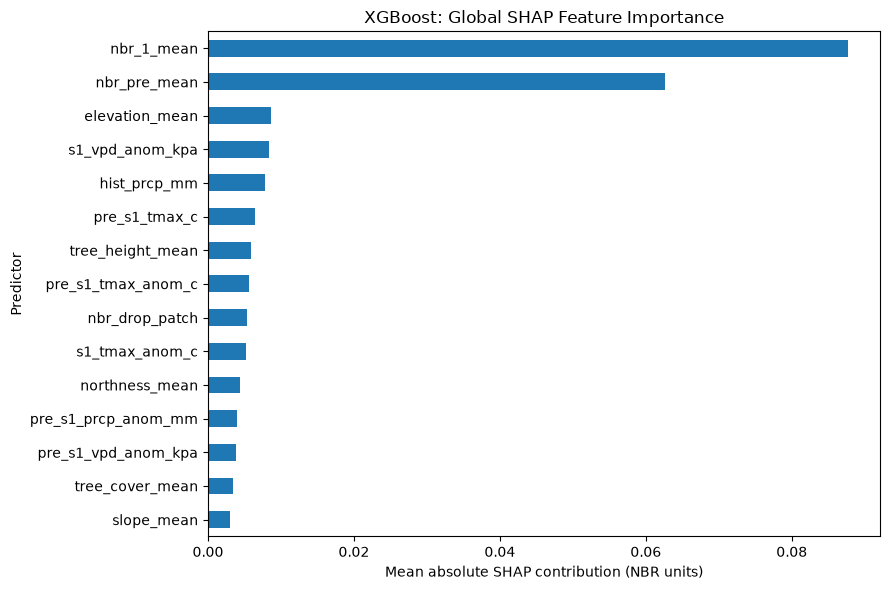


ONE VALIDATION PATCH
Model baseline: 0.3123
Predicted NBR5: 0.3495


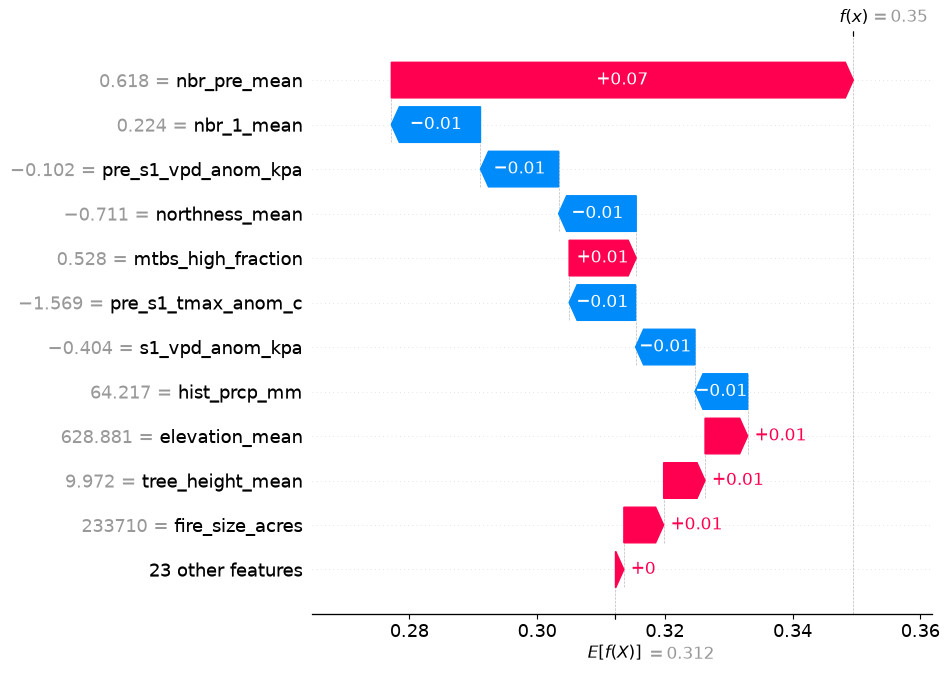

Actual NBR5:     0.4076
Predicted NBR5:  0.3495
Absolute error:  0.0581


In [30]:

# PHASE 5 — BLOCK 1A: XGBOOST SHAP ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

# 1. Sample validation inputs, never 2020 test outcomes
shap_sample = X_val[xgb_features].sample(
    n=400, random_state=42
)

# 2. Apply the exact fitted preprocessing used by XGBoost
preprocess = final_xgb.named_steps["preprocess"]
xgb_model = final_xgb.named_steps["model"]

X_transformed = preprocess.transform(shap_sample)
encoded_names = list(preprocess.get_feature_names_out())

# 3. Calculate TreeSHAP contributions using XGBoost
# Keep the transformed matrix sparse if it is sparse.
booster = xgb_model.get_booster()

contributions = booster.predict(
    xgb.DMatrix(X_transformed),
    pred_contribs=True
)

shap_values = contributions[:, :-1]
base_values = contributions[:, -1]

# 4. Verify SHAP contributions reproduce the predictions
actual_predictions = final_xgb.predict(shap_sample)

assert len(encoded_names) == shap_values.shape[1]
assert np.allclose(
    base_values + shap_values.sum(axis=1),
    actual_predictions,
    atol=1e-4
)

print("SHAP calculation verified!")
print("Explained patches:", len(shap_sample))
print("Encoded features:", len(encoded_names))

# 5. Group one-hot category contributions into raw features
def raw_feature_name(name):
    if name.startswith("categorical__dominant_evt_"):
        return "dominant_evt"
    if name.startswith("categorical__ignition_month_"):
        return "ignition_month"
    return name.split("__", 1)[-1]

feature_groups = {}

for j, name in enumerate(encoded_names):
    feature_groups.setdefault(
        raw_feature_name(name), []
    ).append(j)

grouped_shap = pd.DataFrame({
    name: shap_values[:, indices].sum(axis=1)
    for name, indices in feature_groups.items()
}, index=shap_sample.index)

assert set(grouped_shap.columns) == set(xgb_features)

# 6. Global importance = average absolute SHAP contribution
importance = (
    grouped_shap.abs()
    .mean()
    .sort_values(ascending=False)
)

print("\nTOP 15 PREDICTORS BY MEAN ABSOLUTE SHAP")
display(
    importance.head(15)
    .rename("mean_absolute_SHAP")
    .to_frame()
    .round(5)
)

# 7. Plot global feature importance
ax = (
    importance.head(15)
    .sort_values()
    .plot.barh(figsize=(9, 6))
)

ax.set_xlabel("Mean absolute SHAP contribution (NBR units)")
ax.set_ylabel("Predictor")
ax.set_title("XGBoost: Global SHAP Feature Importance")

plt.tight_layout()
plt.show()

# 8. Explain one individual validation patch
feature_order = list(grouped_shap.columns)

local_explanation = shap.Explanation(
    values=grouped_shap.iloc[0].to_numpy(),
    base_values=float(base_values[0]),
    data=shap_sample.iloc[0][feature_order].to_numpy(),
    feature_names=feature_order,
)

print("\nONE VALIDATION PATCH")
print(f"Model baseline: {base_values[0]:.4f}")
print(f"Predicted NBR5: {actual_predictions[0]:.4f}")

shap.plots.waterfall(
    local_explanation,
    max_display=12
)

actual_nbr5 = float(y_val.loc[shap_sample.index[0]])
predicted_nbr5 = float(actual_predictions[0])

print(f"Actual NBR5:     {actual_nbr5:.4f}")
print(f"Predicted NBR5:  {predicted_nbr5:.4f}")
print(f"Absolute error:  {abs(actual_nbr5 - predicted_nbr5):.4f}")


FIRE-LEVEL WIN COUNTS
winner
Random Forest    19
XGBoost          17
Name: count, dtype: int64

EQUAL-FIRE AVERAGE MAE
rf_mae     0.09327
xgb_mae    0.09142
dtype: float64

TOP 5 FIRES WHERE XGBOOST IS BETTER


,patches,rf_mae,xgb_mae,xgb_advantage,winner
fire_id,,,,,
CA3338011743020180706,1,0.28557,0.24152,0.04404,XGBoost
CA3566212040420190612,2,0.08288,0.04258,0.04030,XGBoost
CA4004012260920191103,322,0.12846,0.10448,0.02398,XGBoost
CA3628411822820190725,776,0.06035,0.04602,0.01433,XGBoost
CA3782611887220190726,1426,0.04876,0.03638,0.01238,XGBoost



TOP 5 FIRES WHERE RANDOM FOREST IS BETTER


,patches,rf_mae,xgb_mae,xgb_advantage,winner
fire_id,,,,,
CA3664611822120180708,135,0.09934,0.11288,-0.01354,Random Forest
CA3432611848120191010,25,0.16843,0.18152,-0.01310,Random Forest
CA4022012217020181007,195,0.02320,0.03493,-0.01173,Random Forest
CA3641011873720181004,816,0.09224,0.10321,-0.01097,Random Forest
CA3982012144020181108,81,0.03382,0.04319,-0.00937,Random Forest


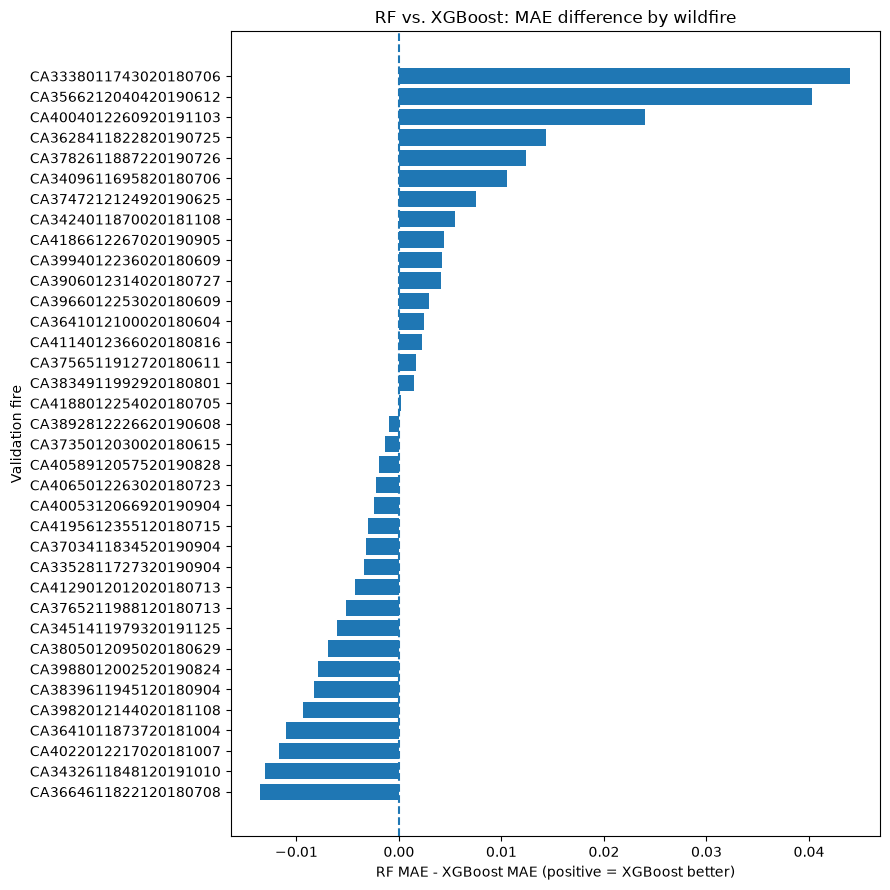

In [31]:

# PHASE 5 — BLOCK 1B: FIRE-LEVEL MODEL COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# All predictions are in the same validation-row order
assert len(y_val) == len(rf_predictions) == len(final_xgb_predictions)
assert len(y_val) == len(val)

fire_errors = pd.DataFrame({
    "fire_id": val["fire_id"].to_numpy(),
    "actual_nbr5": y_val.to_numpy(),
    "rf_prediction": np.asarray(rf_predictions),
    "xgb_prediction": np.asarray(final_xgb_predictions),
})

# Calculate each patch's absolute prediction error
fire_errors["rf_error"] = abs(
    fire_errors["actual_nbr5"] - fire_errors["rf_prediction"]
)

fire_errors["xgb_error"] = abs(
    fire_errors["actual_nbr5"] - fire_errors["xgb_prediction"]
)

# Average the errors separately within each wildfire
fire_comparison = (
    fire_errors.groupby("fire_id")
    .agg(
        patches=("actual_nbr5", "size"),
        rf_mae=("rf_error", "mean"),
        xgb_mae=("xgb_error", "mean"),
    )
)

# Positive advantage = XGBoost has lower error
fire_comparison["xgb_advantage"] = (
    fire_comparison["rf_mae"] - fire_comparison["xgb_mae"]
)

fire_comparison["winner"] = np.where(
    fire_comparison["xgb_advantage"] > 1e-10,
    "XGBoost",
    np.where(
        fire_comparison["xgb_advantage"] < -1e-10,
        "Random Forest",
        "Tie"
    )
)

assert len(fire_comparison) == 36
assert np.isclose(fire_errors["rf_error"].mean(), rf_scores["mae"])
assert np.isclose(fire_errors["xgb_error"].mean(), final_xgb_scores["mae"])

print("FIRE-LEVEL WIN COUNTS")
print(fire_comparison["winner"].value_counts())

print("\nEQUAL-FIRE AVERAGE MAE")
print(
    fire_comparison[["rf_mae", "xgb_mae"]]
    .mean()
    .round(5)
)

print("\nTOP 5 FIRES WHERE XGBOOST IS BETTER")
display(
    fire_comparison.sort_values(
        "xgb_advantage", ascending=False
    ).head(5).round(5)
)

print("\nTOP 5 FIRES WHERE RANDOM FOREST IS BETTER")
display(
    fire_comparison.sort_values(
        "xgb_advantage", ascending=True
    ).head(5).round(5)
)

# Visualize the per-fire differences
ordered = fire_comparison.sort_values("xgb_advantage")

plt.figure(figsize=(9, 9))
plt.barh(
    range(len(ordered)),
    ordered["xgb_advantage"]
)

plt.axvline(0, linestyle="--")
plt.yticks(range(len(ordered)), ordered.index.astype(str))
plt.xlabel("RF MAE - XGBoost MAE (positive = XGBoost better)")
plt.ylabel("Validation fire")
plt.title("RF vs. XGBoost: MAE difference by wildfire")
plt.tight_layout()
plt.show()


In [32]:

# PHASE 5 — BLOCK 1C: SUBGROUP ERROR ANALYSIS

# 1. Sensitivity check: exclude extremely small fires
# This is a diagnostic, not a new model-selection rule.
substantial_fires = fire_comparison.loc[
    fire_comparison["patches"] >= 25
]

print("FIRES WITH AT LEAST 25 ELIGIBLE PATCHES")
print("Fires included:", len(substantial_fires))
print("\nWins:")
print(substantial_fires["winner"].value_counts())

print("\nEqual-fire MAE (this subset):")
display(
    substantial_fires[["rf_mae", "xgb_mae"]]
    .mean()
    .round(5)
)

# 2. Join validation predictors to existing prediction errors
diagnostic = fire_errors.copy()

for feature in [
    "pre_s1_prcp_anom_mm",
    "mtbs_high_fraction",
    "nbr_pre_mean",
]:
    diagnostic[feature] = X_val[feature].to_numpy()

# 3. Define interpretable subgroups
dry = diagnostic["pre_s1_prcp_anom_mm"] < 0
severe = diagnostic["mtbs_high_fraction"] >= 0.5

nbrpre_train_median = X_train["nbr_pre_mean"].median()
high_nbrpre = diagnostic["nbr_pre_mean"] >= nbrpre_train_median

subgroups = {
    "All validation patches": np.ones(len(diagnostic), dtype=bool),
    "Negative precipitation anomaly": dry,
    "Nonnegative precipitation anomaly": ~dry,
    "High burn severity (>=50%)": severe,
    "Lower burn severity (<50%)": ~severe,
    "Dry AND high severity": dry & severe,
    "High pre-fire NBR": high_nbrpre,
    "Lower pre-fire NBR": ~high_nbrpre,
}

results = []

for name, mask in subgroups.items():
    subset = diagnostic.loc[mask]

    results.append({
        "Subgroup": name,
        "Patches": len(subset),
        "Fires": subset["fire_id"].nunique(),
        "RF MAE": subset["rf_error"].mean(),
        "XGB MAE": subset["xgb_error"].mean(),
        "XGB advantage": (
            subset["rf_error"].mean()
            - subset["xgb_error"].mean()
        ),
    })

subgroup_results = pd.DataFrame(results)

print("\nSUBGROUP PERFORMANCE")
display(subgroup_results.round(5))

print("\nPositive XGB advantage means lower XGBoost MAE.")
print("These are descriptive comparisons, not causal effects.")


FIRES WITH AT LEAST 25 ELIGIBLE PATCHES
Fires included: 28

Wins:
winner
Random Forest    18
XGBoost          10
Name: count, dtype: int64

Equal-fire MAE (this subset):


rf_mae     0.08495
xgb_mae    0.08649
dtype: float64


SUBGROUP PERFORMANCE


,Subgroup,Patches,Fires,RF MAE,XGB MAE,XGB advantage
0,All validation patches,19561,36,0.09114,0.09084,0.00030
1,Negative precipitation anomaly,6240,12,0.09619,0.09187,0.00433
2,Nonnegative precipitation anomaly,13321,25,0.08877,0.09036,-0.00159
3,High burn severity (>=50%),2024,19,0.13762,0.13480,0.00282
4,Lower burn severity (<50%),17537,36,0.08577,0.08576,0.00001
5,Dry AND high severity,147,8,0.12697,0.12559,0.00139
6,High pre-fire NBR,8557,20,0.10454,0.10512,-0.00058
7,Lower pre-fire NBR,11004,36,0.08071,0.07974,0.00098



Positive XGB advantage means lower XGBoost MAE.
These are descriptive comparisons, not causal effects.


# Feature ablation experiments

In [33]:

# BLOCK 2 — EXPERIMENT A: NBR-ONLY VS FULL XGBOOST

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# 1. Keep ONLY two predictors
nbr_only_features = ["nbr_pre_mean", "nbr_1_mean"]

assert len(xgb_features) == 34
assert set(nbr_only_features).issubset(xgb_features)

# 2. Create NBR-only version of our tuned XGBoost pipeline
# clone() copies model settings, NOT learned trees.
nbr_only_pipeline = clone(final_xgb)

# Replace the 34-feature preprocessor with a 2-feature version
nbr_only_pipeline.set_params(
    preprocess=ColumnTransformer([
        ("numeric", "passthrough", nbr_only_features),
    ])
)

# 3. Run the same 3 training-only CV folds
nbr_only_fold_maes = []

for train_idx, holdout_idx in cv_splits:
    model = clone(nbr_only_pipeline)

    model.fit(
        X_train.iloc[train_idx][nbr_only_features],
        y_train.iloc[train_idx]
    )

    preds = model.predict(
        X_train.iloc[holdout_idx][nbr_only_features]
    )

    nbr_only_fold_maes.append(
        mean_absolute_error(
            y_train.iloc[holdout_idx],
            preds
        )
    )

nbr_only_cv_mae = float(np.mean(nbr_only_fold_maes))

# 4. Train on all 78 training fires
nbr_only_final = clone(nbr_only_pipeline)

nbr_only_final.fit(
    X_train[nbr_only_features],
    y_train
)

# 5. Predict on 2018-2019 validation fires
nbr_only_predictions = nbr_only_final.predict(
    X_val[nbr_only_features]
)

nbr_only_scores = evaluate_model(
    y_val,
    nbr_only_predictions,
    val["fire_id"]
)

# 6. Compare CV scores
print("TRAINING-ONLY GROUPED CV")
display(pd.DataFrame({
    "Full XGBoost (34 features)": {
        "CV MAE": selected_xgb_cv_mae
    },
    "NBR-only XGBoost (2 features)": {
        "CV MAE": nbr_only_cv_mae
    }
}).T.round(5))

# 7. Compare chronological validation scores
print("\nCHRONOLOGICAL VALIDATION COMPARISON")
ablation_a_comparison = pd.DataFrame({
    "Full XGBoost (34 features)": final_xgb_scores,
    "NBR-only XGBoost (2 features)": nbr_only_scores,
}).T

display(ablation_a_comparison.round(5))

# 8. Calculate incremental benefit of full feature set
mae_benefit = (
    nbr_only_scores["mae"] - final_xgb_scores["mae"]
)

relative_benefit = (
    mae_benefit / nbr_only_scores["mae"] * 100
)

print("\nADDITIONAL 32 FEATURES — VALIDATION BENEFIT")
print(f"MAE reduction: {mae_benefit:+.5f}")
print(f"Relative MAE reduction: {relative_benefit:+.2f}%")
print("Positive means the full 34-feature model is better.")


TRAINING-ONLY GROUPED CV


,CV MAE
Full XGBoost (34 features),0.06230
NBR-only XGBoost (2 features),0.06716



CHRONOLOGICAL VALIDATION COMPARISON


,mae,rmse,r2,equal_fire_mae
Full XGBoost (34 features),0.09084,0.11825,0.61566,0.09142
NBR-only XGBoost (2 features),0.08438,0.11150,0.65824,0.08630



ADDITIONAL 32 FEATURES — VALIDATION BENEFIT
MAE reduction: -0.00646
Relative MAE reduction: -7.65%
Positive means the full 34-feature model is better.


In [34]:

# BLOCK 2 — EXPERIMENT B: REMOVE CLIMATE FEATURES

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Identify approved climate predictors
climate_features = [
    f for f in xgb_features
    if f.startswith(("hist_", "pre_s1_", "s1_"))
]

no_climate_features = [
    f for f in xgb_features
    if f not in climate_features
]

categorical = ["dominant_evt", "ignition_month"]
numeric = [
    f for f in no_climate_features
    if f not in categorical
]

print("Climate features removed:", len(climate_features))
print("Features retained:", len(no_climate_features))
print("Removed:", climate_features)

assert len(climate_features) == 16
assert len(no_climate_features) == 18

# Same selected XGBoost hyperparameters, different inputs
no_climate_pipeline = clone(final_xgb)

no_climate_pipeline.set_params(
    preprocess=ColumnTransformer([
        ("numeric", "passthrough", numeric),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical),
    ])
)

# Training-only grouped CV
no_climate_fold_maes = []

for train_idx, holdout_idx in cv_splits:
    model = clone(no_climate_pipeline)

    model.fit(
        X_train.iloc[train_idx][no_climate_features],
        y_train.iloc[train_idx]
    )

    predictions = model.predict(
        X_train.iloc[holdout_idx][no_climate_features]
    )

    no_climate_fold_maes.append(
        mean_absolute_error(
            y_train.iloc[holdout_idx],
            predictions
        )
    )

no_climate_cv_mae = float(np.mean(no_climate_fold_maes))

# Fit on all training fires and evaluate chronologically
no_climate_final = clone(no_climate_pipeline)

no_climate_final.fit(
    X_train[no_climate_features], y_train
)

no_climate_predictions = no_climate_final.predict(
    X_val[no_climate_features]
)

no_climate_scores = evaluate_model(
    y_val, no_climate_predictions, val["fire_id"]
)

print("\nGROUPED CV MAE")
display(pd.Series({
    "Full XGBoost": selected_xgb_cv_mae,
    "No-climate XGBoost": no_climate_cv_mae,
    "NBR-only XGBoost": nbr_only_cv_mae
}).round(5))

print("\nCHRONOLOGICAL VALIDATION")
display(pd.DataFrame({
    "Full (34 features)": final_xgb_scores,
    "No climate (18 features)": no_climate_scores,
    "NBR-only (2 features)": nbr_only_scores
}).T.round(5))


Climate features removed: 16
Features retained: 18
Removed: ['hist_prcp_mm', 'hist_tmax_c', 'hist_tmin_c', 'hist_s1_vpd_kpa', 'pre_s1_prcp_mm', 'pre_s1_tmax_c', 'pre_s1_tmin_c', 'pre_s1_vpd_kpa', 'pre_s1_prcp_anom_mm', 'pre_s1_tmax_anom_c', 'pre_s1_tmin_anom_c', 'pre_s1_vpd_anom_kpa', 's1_prcp_anom_mm', 's1_tmax_anom_c', 's1_tmin_anom_c', 's1_vpd_anom_kpa']

GROUPED CV MAE


Full XGBoost          0.06230
No-climate XGBoost    0.06055
NBR-only XGBoost      0.06716
dtype: float64


CHRONOLOGICAL VALIDATION


,mae,rmse,r2,equal_fire_mae
Full (34 features),0.09084,0.11825,0.61566,0.09142
No climate (18 features),0.07510,0.10172,0.71561,0.08352
NBR-only (2 features),0.08438,0.11150,0.65824,0.08630


In [35]:

# BLOCK 2 — RIDGE AND RF FEATURE INTERPRETATION

import pandas as pd

# RIDGE: Standardized numerical coefficients only
ridge_coefficients = pd.Series(
    final_ridge.named_steps["model"].coef_[:len(numeric_features)],
    index=numeric_features
)

print("RIDGE — TOP POSITIVE COEFFICIENTS")
display(ridge_coefficients.nlargest(10).round(5))

print("\nRIDGE — TOP NEGATIVE COEFFICIENTS")
display(ridge_coefficients.nsmallest(10).round(5))


# RANDOM FOREST: Aggregate importance back to raw features
rf_encoded_names = (
    final_rf.named_steps["preprocess"]
    .get_feature_names_out()
)

def rf_original_feature(name):
    if name.startswith("categorical__dominant_evt_"):
        return "dominant_evt"
    if name.startswith("categorical__ignition_month_"):
        return "ignition_month"
    return name.split("__", 1)[-1]

rf_importance = pd.Series(
    final_rf.named_steps["model"].feature_importances_,
    index=[rf_original_feature(n) for n in rf_encoded_names]
).groupby(level=0).sum().sort_values(ascending=False)

print("\nRANDOM FOREST — TOP 15 FEATURES")
display(rf_importance.head(15).round(5))

assert len(rf_importance) == 34
assert abs(rf_importance.sum() - 1.0) < 1e-6


RIDGE — TOP POSITIVE COEFFICIENTS


nbr_1_mean                    0.08497
nbr_pre_mean                  0.08137
pre_s1_tmax_c                 0.01554
s1_tmin_anom_c                0.01241
tree_cover_mean               0.01225
pre_s1_vpd_kpa                0.01139
hist_prcp_mm                  0.00987
slope_mean                    0.00847
pre_s1_tmin_anom_c            0.00782
mtbs_unburned_low_fraction    0.00776
dtype: float64


RIDGE — TOP NEGATIVE COEFFICIENTS


pre_s1_prcp_mm           -0.01502
mtbs_low_fraction        -0.01005
tree_height_mean         -0.00909
hist_tmin_c              -0.00810
hist_s1_vpd_kpa          -0.00658
s1_vpd_anom_kpa          -0.00389
s1_prcp_anom_mm          -0.00384
dominant_evt_fraction    -0.00275
mtbs_moderate_fraction   -0.00174
eastness_mean            -0.00169
dtype: float64


RANDOM FOREST — TOP 15 FEATURES


nbr_1_mean             0.53817
nbr_pre_mean           0.25340
tree_cover_mean        0.03840
elevation_mean         0.01583
s1_vpd_anom_kpa        0.01462
hist_prcp_mm           0.01323
nbr_drop_patch         0.01286
pre_s1_tmax_c          0.01122
pre_s1_vpd_anom_kpa    0.00803
pre_s1_prcp_anom_mm    0.00734
pre_s1_tmin_anom_c     0.00718
pre_s1_tmin_c          0.00715
pre_s1_tmax_anom_c     0.00687
pre_s1_prcp_mm         0.00652
s1_prcp_anom_mm        0.00573
dtype: float64

In [36]:

# FINAL ABLATION — RANDOM FOREST WITHOUT CLIMATE

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Reuse the 18-feature set from our XGBoost ablation
assert len(no_climate_features) == 18

rf_no_climate_numeric = [
    f for f in no_climate_features
    if f not in ["dominant_evt", "ignition_month"]
]

# Same RF hyperparameters, just fewer features
rf_no_climate = clone(final_rf)

rf_no_climate.set_params(
    preprocess=ColumnTransformer([
        ("numeric", "passthrough", rf_no_climate_numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         ["dominant_evt", "ignition_month"]),
    ])
)

# 1. Same training-only grouped CV folds
rf_nc_fold_maes = []

for train_idx, holdout_idx in cv_splits:
    model = clone(rf_no_climate)

    model.fit(
        X_train.iloc[train_idx][no_climate_features],
        y_train.iloc[train_idx]
    )

    preds = model.predict(
        X_train.iloc[holdout_idx][no_climate_features]
    )

    rf_nc_fold_maes.append(
        mean_absolute_error(
            y_train.iloc[holdout_idx],
            preds
        )
    )

rf_nc_cv_mae = float(np.mean(rf_nc_fold_maes))

# 2. Fit on all training fires
rf_nc_final = clone(rf_no_climate)

rf_nc_final.fit(
    X_train[no_climate_features],
    y_train
)

# 3. Evaluate on 2018-2019 validation
rf_nc_predictions = rf_nc_final.predict(
    X_val[no_climate_features]
)

rf_nc_scores = evaluate_model(
    y_val,
    rf_nc_predictions,
    val["fire_id"]
)

# 4. Compare full and no-climate versions
print("GROUPED CROSS-VALIDATION MAE")
display(pd.Series({
    "Full RF": rf_cv_mae,
    "No-climate RF": rf_nc_cv_mae,
    "Full XGBoost": selected_xgb_cv_mae,
    "No-climate XGBoost": no_climate_cv_mae,
}).round(5))

print("\nCHRONOLOGICAL VALIDATION COMPARISON")
display(pd.DataFrame({
    "Full RF": rf_scores,
    "No-climate RF": rf_nc_scores,
    "Full XGBoost": final_xgb_scores,
    "No-climate XGBoost": no_climate_scores,
}).T.sort_values("mae").round(5))


GROUPED CROSS-VALIDATION MAE


Full RF               0.06420
No-climate RF         0.06496
Full XGBoost          0.06230
No-climate XGBoost    0.06055
dtype: float64


CHRONOLOGICAL VALIDATION COMPARISON


,mae,rmse,r2,equal_fire_mae
No-climate RF,0.07399,0.09974,0.72657,0.08259
No-climate XGBoost,0.07510,0.10172,0.71561,0.08352
Full XGBoost,0.09084,0.11825,0.61566,0.09142
Full RF,0.09114,0.11746,0.62073,0.09327


No-climate SHAP verified!
Validation patches explained: 400
Original predictors: 18

TOP 12 NO-CLIMATE FEATURES


nbr_1_mean           0.08487
nbr_pre_mean         0.06191
elevation_mean       0.01610
fire_size_acres      0.01020
ignition_month       0.00850
tree_height_mean     0.00763
tree_cover_mean      0.00611
dominant_evt         0.00521
nbr_drop_patch       0.00489
slope_mean           0.00423
northness_mean       0.00416
mtbs_low_fraction    0.00287
dtype: float32


FULL VS NO-CLIMATE SHAP IMPORTANCE


,Full XGBoost,No-climate XGBoost
nbr_1_mean,0.08771,0.08487
nbr_pre_mean,0.06262,0.06191
elevation_mean,0.00861,0.01610
fire_size_acres,0.00266,0.01020
ignition_month,0.00222,0.00850
tree_height_mean,0.00591,0.00763
tree_cover_mean,0.00345,0.00611
dominant_evt,0.00151,0.00521
nbr_drop_patch,0.00534,0.00489
slope_mean,0.00301,0.00423


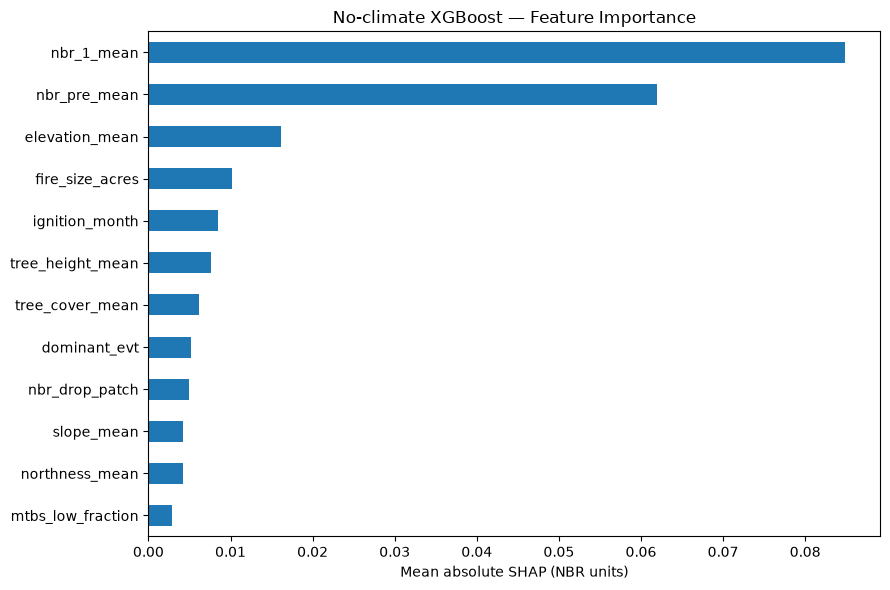

In [37]:

# STEP 1 — NO-CLIMATE XGBOOST SHAP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

# Same 400 validation rows used in our original SHAP analysis
sample_nc = X_val[no_climate_features].sample(
    n=400, random_state=42
)

preprocess_nc = no_climate_final.named_steps["preprocess"]
booster_nc = no_climate_final.named_steps["model"].get_booster()

X_encoded_nc = preprocess_nc.transform(sample_nc)
encoded_names_nc = preprocess_nc.get_feature_names_out()

# Calculate SHAP contributions
contrib_nc = booster_nc.predict(
    xgb.DMatrix(X_encoded_nc),
    pred_contribs=True
)

shap_nc = contrib_nc[:, :-1]
base_nc = contrib_nc[:, -1]

# Verify contributions reconstruct predictions
pred_nc = no_climate_final.predict(sample_nc)

assert np.allclose(
    base_nc + shap_nc.sum(axis=1),
    pred_nc,
    atol=1e-4
)

# Combine one-hot categorical features
def nc_raw_feature(name):
    if name.startswith("categorical__dominant_evt_"):
        return "dominant_evt"
    if name.startswith("categorical__ignition_month_"):
        return "ignition_month"
    return name.split("__", 1)[-1]

grouped_nc = {}

for j, name in enumerate(encoded_names_nc):
    raw_name = nc_raw_feature(name)
    grouped_nc.setdefault(raw_name, []).append(j)

nc_shap_importance = pd.Series({
    name: np.abs(shap_nc[:, indices].sum(axis=1)).mean()
    for name, indices in grouped_nc.items()
}).sort_values(ascending=False)

assert set(nc_shap_importance.index) == set(no_climate_features)

print("No-climate SHAP verified!")
print("Validation patches explained:", len(sample_nc))
print("Original predictors:", len(no_climate_features))

print("\nTOP 12 NO-CLIMATE FEATURES")
display(nc_shap_importance.head(12).round(5))

# Compare with previous full-model SHAP
print("\nFULL VS NO-CLIMATE SHAP IMPORTANCE")
shap_comparison = pd.DataFrame({
    "Full XGBoost": importance,
    "No-climate XGBoost": nc_shap_importance
})

display(shap_comparison.loc[
    nc_shap_importance.head(12).index
].round(5))

# Plot
ax = nc_shap_importance.head(12).sort_values().plot.barh(
    figsize=(9, 6)
)
ax.set_xlabel("Mean absolute SHAP (NBR units)")
ax.set_title("No-climate XGBoost — Feature Importance")
plt.tight_layout()
plt.show()


In [38]:

# STEP 2 — RECORD PHASE 5 ABLATIONS IN MLFLOW
# No retraining or additional evaluation

import mlflow
import mlflow.sklearn
import numpy as np

mlflow.set_tracking_uri(
    f"sqlite:///{(root / 'mlflow.db').as_posix()}"
)
mlflow.set_experiment("P1 - Wildfire Recovery - Phase 5")

def log_ablation(
    run_name, model, feature_list,
    scores, fold_maes, algorithm
):
    # Extract settings from the already-fitted model
    fitted_settings = model.named_steps["model"].get_params()

    if algorithm == "XGBoost":
        keys = [
            "n_estimators", "max_depth", "learning_rate",
            "min_child_weight", "subsample",
            "colsample_bytree", "reg_lambda",
            "random_state"
        ]
    else:
        keys = [
            "n_estimators", "max_depth",
            "min_samples_leaf", "min_samples_split",
            "max_features", "bootstrap", "random_state"
        ]

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params({
            "algorithm": algorithm,
            "dataset": "patch_model_eligible_terrain_v2",
            "feature_set": run_name,
            "n_features": len(feature_list),
            "cv_method": "GroupKFold",
            "cv_folds": 3,
            "hyperparameters_retuned": False,
            **{key: fitted_settings[key] for key in keys}
        })

        mlflow.log_metrics({
            "cv_mae": float(np.mean(fold_maes)),
            "cv_std_mae": float(np.std(fold_maes)),
            **{
                f"val_{k}": float(v)
                for k, v in scores.items()
            }
        })

        # Preserve exact input feature list
        mlflow.log_dict({
            "features": list(feature_list),
            "feature_count": len(feature_list),
            "trained_on": "2015-2017",
            "validated_on": "2018-2019"
        }, "inputs/feature_set.json")

        # Save fitted pipeline
        if algorithm == "RandomForest":
            mlflow.sklearn.log_model(
                sk_model=model,
                name="model",
                skops_trusted_types=[
                    "sklearn.tree._tree.Tree"
                ]
            )
        else:
            mlflow.sklearn.log_model(
                sk_model=model,
                name="model",
                serialization_format="cloudpickle"
            )

    print(f"{run_name} logged: {run.info.run_id}")


# 1. NBR-only XGBoost
log_ablation(
    "xgboost_nbr_only",
    nbr_only_final,
    nbr_only_features,
    nbr_only_scores,
    nbr_only_fold_maes,
    "XGBoost"
)

# 2. No-climate XGBoost
log_ablation(
    "xgboost_no_climate",
    no_climate_final,
    no_climate_features,
    no_climate_scores,
    no_climate_fold_maes,
    "XGBoost"
)

# 3. No-climate Random Forest
log_ablation(
    "random_forest_no_climate",
    rf_nc_final,
    no_climate_features,
    rf_nc_scores,
    rf_nc_fold_maes,
    "RandomForest"
)

print("\nAll three ablation experiments recorded!")


2026/10/31 21:38:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/31 21:39:19 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/31 21:39:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


xgboost_nbr_only logged: cb37cc8997bf404985ed30eab5f4ffd0


2026/10/31 21:39:27 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


xgboost_no_climate logged: 2cb3267c3dac4d4c80fe118e274637be


2026/10/31 21:39:42 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


random_forest_no_climate logged: b175c6f10eeb4ebfa8c0930192468d39

All three ablation experiments recorded!


In [39]:

# FINAL EXPERIMENT — OPTUNA FOR NO-CLIMATE XGBOOST
# 18 predictors, training-only grouped CV

import optuna
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

optuna.logging.set_verbosity(optuna.logging.WARNING)

assert len(no_climate_features) == 18

# 1. Define the Optuna objective
def no_climate_objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 100, 700, step=50
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 2, 12
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.008, 0.18, log=True
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 30
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.65, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.65, 1.0
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.03, 20.0, log=True
        ),
    }

    fold_maes = []

    for train_idx, holdout_idx in cv_splits:

        model = clone(no_climate_final)

        model.set_params(**{
            f"model__{k}": v
            for k, v in params.items()
        })

        model.fit(
            X_train.iloc[train_idx][no_climate_features],
            y_train.iloc[train_idx]
        )

        preds = model.predict(
            X_train.iloc[holdout_idx][no_climate_features]
        )

        fold_maes.append(
            mean_absolute_error(
                y_train.iloc[holdout_idx],
                preds
            )
        )

    score = float(np.mean(fold_maes))
    trial.set_user_attr("fold_maes", fold_maes)

    print(f"Trial {trial.number + 1}: CV MAE = {score:.5f}")

    return score


# 2. Create a new study specifically for 18 features
study_nc = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

# Include our existing no-climate configuration
# as Trial 1, so we have a fair baseline.
search_params = [
    "n_estimators",
    "max_depth",
    "learning_rate",
    "min_child_weight",
    "subsample",
    "colsample_bytree",
    "reg_lambda",
]

incumbent_params = (
    no_climate_final.named_steps["model"].get_params()
)

study_nc.enqueue_trial({
    k: incumbent_params[k] for k in search_params
})

# 3. Run bounded tuning
study_nc.optimize(
    no_climate_objective,
    n_trials=50,
    timeout=1800,  # 30 minutes
    n_jobs=1,
)

# 4. Review results
print("\nOPTUNA RESULTS")
print("Completed trials:",
      sum(t.state == optuna.trial.TrialState.COMPLETE
          for t in study_nc.trials))

print(f"Previous no-climate CV MAE: {no_climate_cv_mae:.5f}")
print(f"New best CV MAE: {study_nc.best_value:.5f}")

print("\nBEST HYPERPARAMETERS")
for k, v in study_nc.best_params.items():
    print(f"{k}: {v}")

# 5. Train the selected configuration on ALL training fires
xgb_nc_tuned = clone(no_climate_final)

xgb_nc_tuned.set_params(**{
    f"model__{k}": v
    for k, v in study_nc.best_params.items()
})

xgb_nc_tuned.fit(
    X_train[no_climate_features],
    y_train
)

# 6. Evaluate on chronological validation
xgb_nc_tuned_preds = xgb_nc_tuned.predict(
    X_val[no_climate_features]
)

xgb_nc_tuned_scores = evaluate_model(
    y_val,
    xgb_nc_tuned_preds,
    val["fire_id"]
)

# 7. Compare against existing no-climate models
print("\nFINAL NO-CLIMATE MODEL COMPARISON")

comparison_nc = pd.DataFrame({
    "RF no-climate": rf_nc_scores,
    "XGBoost no-climate (original settings)": no_climate_scores,
    "XGBoost no-climate (retuned)": xgb_nc_tuned_scores,
}).T.sort_values("mae")

display(comparison_nc.round(5))

print("\nCV COMPARISON")
display(pd.Series({
    "RF no-climate": rf_nc_cv_mae,
    "XGBoost no-climate original": no_climate_cv_mae,
    "XGBoost no-climate retuned": study_nc.best_value,
}).round(5))

print("\nMAE DIFFERENCE VS RF:")
print(
    f"{rf_nc_scores['mae'] - xgb_nc_tuned_scores['mae']:+.5f}"
)
print("Positive means retuned XGBoost is better.")

# 8. Save trial history locally, outside Git
trials_dir = root / "mlruns"
trials_dir.mkdir(exist_ok=True)

study_nc.trials_dataframe().to_csv(
    trials_dir / "xgb_no_climate_optuna.csv",
    index=False
)

print("\nNo-climate Optuna history saved.")


Trial 1: CV MAE = 0.06055
Trial 2: CV MAE = 0.06076
Trial 3: CV MAE = 0.06135
Trial 4: CV MAE = 0.06334
Trial 5: CV MAE = 0.06245
Trial 6: CV MAE = 0.06231
Trial 7: CV MAE = 0.06048
Trial 8: CV MAE = 0.07023
Trial 9: CV MAE = 0.06135
Trial 10: CV MAE = 0.07971
Trial 11: CV MAE = 0.06063
Trial 12: CV MAE = 0.06090
Trial 13: CV MAE = 0.06338
Trial 14: CV MAE = 0.06338
Trial 15: CV MAE = 0.06106
Trial 16: CV MAE = 0.06050
Trial 17: CV MAE = 0.06248
Trial 18: CV MAE = 0.06162
Trial 19: CV MAE = 0.06005
Trial 20: CV MAE = 0.06037
Trial 21: CV MAE = 0.06086
Trial 22: CV MAE = 0.06411
Trial 23: CV MAE = 0.06016
Trial 24: CV MAE = 0.06056
Trial 25: CV MAE = 0.06034
Trial 26: CV MAE = 0.06016
Trial 27: CV MAE = 0.06059
Trial 28: CV MAE = 0.06003
Trial 29: CV MAE = 0.06152
Trial 30: CV MAE = 0.05976
Trial 31: CV MAE = 0.06010
Trial 32: CV MAE = 0.05993
Trial 33: CV MAE = 0.06030
Trial 34: CV MAE = 0.06008
Trial 35: CV MAE = 0.06048
Trial 36: CV MAE = 0.05987
Trial 37: CV MAE = 0.05966
Trial 38: 

,mae,rmse,r2,equal_fire_mae
RF no-climate,0.07399,0.09974,0.72657,0.08259
XGBoost no-climate (original settings),0.07510,0.10172,0.71561,0.08352
XGBoost no-climate (retuned),0.07525,0.10114,0.71882,0.08178



CV COMPARISON


RF no-climate                  0.06496
XGBoost no-climate original    0.06055
XGBoost no-climate retuned     0.05942
dtype: float64


MAE DIFFERENCE VS RF:
-0.00126
Positive means retuned XGBoost is better.

No-climate Optuna history saved.
